# DATA 266 - Lab 2 - Part 2: Fine-tuning Stable Diffusion 1.5 with LoRA
## Notebook 2 of 3: Fine-tuning (task 2.2)

Two runs are trained on the same data, with the same number of steps, the same batch size, the same learning rate and the same seed. The **only** difference is the LoRA rank:

- **Run 1:** LoRA, rank 8
- **Run 2:** LoRA, rank 32

Training uses the LoRA example script from `diffusers` (`scripts/part2/train_text_to_image_lora.py`, unchanged). A small wrapper (`scripts/part2/run_training.py`) caps the GPU memory at 15 GB, so the runs also fit on a 16 GB GPU such as a Kaggle or Colab T4, and records the peak memory and the training time.

The results are written to `outputs/part2/metrics/training_table.csv` and used by notebook 3. The trained LoRA files are uploaded to Hugging Face in notebook 3 (model files are not stored in Git).

In [1]:
# Cell 1 - Reproducibility and environment information

import os
import sys
import random
import subprocess
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import torch

SEED = 266

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def library_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


# Git commit. Git is not always on the PATH inside a notebook kernel, so a few usual places are tried
commit = ""
for git in ["git", r"C:\Program Files\Git\cmd\git.exe", os.path.expanduser(r"~\AppData\Local\Programs\Git\cmd\git.exe")]:
    try:
        result = subprocess.run([git, "rev-parse", "--short", "HEAD"], capture_output=True, text=True)
        commit = result.stdout.strip()
        break
    except FileNotFoundError:
        continue

run_info = {
    "commit": commit or "no Git repository here",
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "diffusers": library_version("diffusers"),
    "peft": library_version("peft"),
    "accelerate": library_version("accelerate"),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "seed": SEED
}

print(run_info)

if torch.cuda.is_available():
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

{'commit': '9cf9213', 'python': '3.11.18', 'torch': '2.14.1+cu130', 'diffusers': '0.42.1', 'peft': '0.21.2', 'accelerate': '1.15.0', 'gpu': 'NVIDIA GeForce RTX 4090', 'seed': 266}
GPU memory: 23.99 GB


## 1. Settings

Both runs share every setting except the rank. With `lora_alpha` equal to the rank (the way the diffusers script sets it), the LoRA update has the same scale in both runs.

**How the step budget was chosen.** A first trial with 1,500 steps (8 epochs, 6,000 images seen) changed the style only partly: a quick look at one generated image still showed a painted background instead of the plain white background of the dataset. The reference recipe of the diffusers Pokemon LoRA example sees about 15,000 images, so the budget was raised to **3,000 steps (about 16 epochs, 12,000 images seen)**. This was decided from that recipe and from looking at one image, not from any test metric.

In [2]:
import json
import time
import shutil
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from safetensors import safe_open
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"

DATA_DIR = Path("../data/part2")
OUT_DIR = Path("../outputs/part2")
TRAIN_DIR = OUT_DIR / "data_prep" / "images" / "train"
RUN_DIR = OUT_DIR / "runs"
METRIC_DIR = OUT_DIR / "metrics"
SCRIPT_DIR = Path("../scripts/part2").resolve()

# The same settings for both runs
SETTINGS = {
    "resolution": 512,
    "train_batch_size": 4,
    "gradient_accumulation_steps": 1,
    "max_train_steps": 3000,
    "learning_rate": 1e-4,
    "lr_scheduler": "cosine",
    "lr_warmup_steps": 0,
    "mixed_precision": "fp16",
    "seed": SEED,
}

# The only difference between the runs
RUNS = {
    "run1_lora_r8": {"rank": 8},
    "run2_lora_r32": {"rank": 32},
}

MEMORY_LIMIT_GB = 15     # so that the runs also fit on a 16 GB GPU
RETRAIN = True           # False: reuse finished runs instead of training again

METRIC_DIR.mkdir(parents=True, exist_ok=True)

print(json.dumps(SETTINGS, indent=2))
print("Runs:", RUNS)

{
  "resolution": 512,
  "train_batch_size": 4,
  "gradient_accumulation_steps": 1,
  "max_train_steps": 3000,
  "learning_rate": 0.0001,
  "lr_scheduler": "cosine",
  "lr_warmup_steps": 0,
  "mixed_precision": "fp16",
  "seed": 266
}
Runs: {'run1_lora_r8': {'rank': 8}, 'run2_lora_r32': {'rank': 32}}


## 2. Check the inputs

The training images come from notebook 1. The 20 prompts must already be committed to Git (their commit time is shown below), because the lab requires them to be fixed before training ends.

In [3]:
n_train = len(list(TRAIN_DIR.glob("*.png")))
n_captions = len((TRAIN_DIR / "metadata.jsonl").read_text(encoding="utf-8").strip().split("\n"))
print("Training images:  ", n_train)
print("Training captions:", n_captions)
assert n_train == n_captions and n_train > 0, "run notebook 1 first"

prompts = json.loads((DATA_DIR / "prompts.json").read_text(encoding="utf-8"))
print("Fixed prompts:    ", len(prompts))

git_time = subprocess.run(
    [git, "log", "-1", "--format=%ci", "--", "data/part2/prompts.json"],
    capture_output=True, text=True, cwd=".."
).stdout.strip()
print("prompts.json was committed to Git at:", git_time or "NOT COMMITTED YET - commit it before training")
print("Training starts at:                  ", time.strftime("%Y-%m-%d %H:%M:%S"))

steps_per_epoch = n_train / (SETTINGS["train_batch_size"] * SETTINGS["gradient_accumulation_steps"])
print(f"One epoch is {steps_per_epoch:.0f} steps, so {SETTINGS['max_train_steps']} steps are "
      f"{SETTINGS['max_train_steps'] / steps_per_epoch:.1f} epochs")

Training images:   747
Training captions: 747
Fixed prompts:     20
prompts.json was committed to Git at: 2026-11-06 17:04:35 -0800
Training starts at:                   2026-11-06 18:20:45
One epoch is 187 steps, so 3000 steps are 16.1 epochs


## 3. Training function

In [4]:
def train(run_name, rank):
    """Train one LoRA run with the diffusers script and return its measurements."""
    output_dir = (RUN_DIR / run_name).resolve()
    summary_file = output_dir / "summary.json"

    if summary_file.exists() and (output_dir / "pytorch_lora_weights.safetensors").exists() and not RETRAIN:
        print(f"{run_name}: finished run found, not training again")
        return json.loads(summary_file.read_text())

    command = [
        sys.executable, str(SCRIPT_DIR / "run_training.py"),
        "--memory_limit_gb", str(MEMORY_LIMIT_GB),
        "--summary", str(summary_file),
        "--",
        "--pretrained_model_name_or_path", BASE_MODEL,
        "--variant", "fp16",
        "--train_data_dir", str(TRAIN_DIR.resolve()),
        "--image_column", "image",
        "--caption_column", "text",
        "--resolution", str(SETTINGS["resolution"]),
        "--center_crop",
        "--random_flip",
        "--train_batch_size", str(SETTINGS["train_batch_size"]),
        "--gradient_accumulation_steps", str(SETTINGS["gradient_accumulation_steps"]),
        "--gradient_checkpointing",
        "--max_train_steps", str(SETTINGS["max_train_steps"]),
        "--learning_rate", str(SETTINGS["learning_rate"]),
        "--lr_scheduler", SETTINGS["lr_scheduler"],
        "--lr_warmup_steps", str(SETTINGS["lr_warmup_steps"]),
        "--mixed_precision", SETTINGS["mixed_precision"],
        "--seed", str(SETTINGS["seed"]),
        "--rank", str(rank),
        "--checkpointing_steps", "100000",       # no intermediate checkpoints
        "--dataloader_num_workers", "0",
        "--output_dir", str(output_dir),
    ]

    # Start with an empty log folder, so the loss log of an earlier run can never be mixed with this one
    shutil.rmtree(output_dir / "logs", ignore_errors=True)
    output_dir.mkdir(parents=True, exist_ok=True)
    log_file = output_dir / "training.log"
    print(f"{run_name}: training with rank {rank} ...")
    start = time.time()
    with open(log_file, "w", encoding="utf-8") as log:
        completed = subprocess.run(command, stdout=log, stderr=subprocess.STDOUT)
    print(f"{run_name}: finished in {(time.time() - start) / 60:.1f} minutes (exit code {completed.returncode})")

    if completed.returncode != 0:
        tail = log_file.read_text(encoding="utf-8", errors="replace").replace("\r", "\n").strip().split("\n")[-15:]
        print("\n".join(tail))
        raise RuntimeError(f"training of {run_name} failed, see {log_file}")

    # The log is full of progress-bar lines. Keep only a short readable version.
    lines = log_file.read_text(encoding="utf-8", errors="replace").replace("\r", "\n").split("\n")
    keep = [l for l in lines if l.strip() and "it/s" not in l and "s/it" not in l]
    log_file.write_text("\n".join(keep[-60:]), encoding="utf-8")

    return json.loads(summary_file.read_text())

## 4. Run 1: LoRA rank 8

In [5]:
summaries = {}
summaries["run1_lora_r8"] = train("run1_lora_r8", RUNS["run1_lora_r8"]["rank"])
print(json.dumps({k: v for k, v in summaries["run1_lora_r8"].items() if k != "arguments"}, indent=2))

run1_lora_r8: training with rank 8 ...


run1_lora_r8: finished in 16.3 minutes (exit code 0)
{
  "gpu": "NVIDIA GeForce RTX 4090",
  "memory_limit_gb": 15.0,
  "peak_memory_allocated_gb": 3.7,
  "peak_memory_reserved_gb": 4.22,
  "training_seconds": 974.2
}


## 5. Run 2: LoRA rank 32

In [6]:
summaries["run2_lora_r32"] = train("run2_lora_r32", RUNS["run2_lora_r32"]["rank"])
print(json.dumps({k: v for k, v in summaries["run2_lora_r32"].items() if k != "arguments"}, indent=2))

run2_lora_r32: training with rank 32 ...


run2_lora_r32: finished in 16.2 minutes (exit code 0)
{
  "gpu": "NVIDIA GeForce RTX 4090",
  "memory_limit_gb": 15.0,
  "peak_memory_allocated_gb": 3.75,
  "peak_memory_reserved_gb": 4.29,
  "training_seconds": 967.0
}


## 6. Training table

The number of trainable parameters is counted from the saved LoRA file. The training time is the wall-clock time of the whole script (it includes about 10-20 seconds for loading the model). GPU-hours is that time in hours, because one GPU was used. The final loss is the average over the last 100 steps.

In [7]:
def lora_parameter_count(run_name):
    file = safe_open(str(RUN_DIR / run_name / "pytorch_lora_weights.safetensors"), "pt")
    return sum(file.get_tensor(key).numel() for key in file.keys())


def loss_curve(run_name):
    events = EventAccumulator(str(RUN_DIR / run_name / "logs" / "text2image-fine-tune"))
    events.Reload()
    return pd.Series([e.value for e in events.Scalars("train_loss")])


UNET_PARAMETERS = 859_520_964       # from the base model (counted in the environment check)

rows, curves = [], {}
for run_name, run in RUNS.items():
    summary = summaries[run_name]
    curves[run_name] = loss_curve(run_name)
    trainable = lora_parameter_count(run_name)
    rows.append({
        "run": run_name,
        "method": "LoRA (attention layers of the UNet)",
        "rank": run["rank"],
        "trainable_parameters": trainable,
        "share_of_unet": f"{100 * trainable / UNET_PARAMETERS:.2f}%",
        "learning_rate": SETTINGS["learning_rate"],
        "steps": SETTINGS["max_train_steps"],
        "batch_size": SETTINGS["train_batch_size"] * SETTINGS["gradient_accumulation_steps"],
        "epochs": round(SETTINGS["max_train_steps"] * SETTINGS["train_batch_size"] / n_train, 1),
        "peak_gpu_memory_gb": summary["peak_memory_allocated_gb"],
        "peak_gpu_memory_reserved_gb": summary["peak_memory_reserved_gb"],
        "training_minutes": round(summary["training_seconds"] / 60, 1),
        "gpu_hours": round(summary["training_seconds"] / 3600, 3),
        "final_loss": round(float(curves[run_name].tail(100).mean()), 4),
        "seed": SETTINGS["seed"],
    })

training_table = pd.DataFrame(rows)
training_table.to_csv(METRIC_DIR / "training_table.csv", index=False)
print(training_table.T.to_string(header=False))
print("\nSaved:", METRIC_DIR / "training_table.csv")

run                                                 run1_lora_r8                        run2_lora_r32
method                       LoRA (attention layers of the UNet)  LoRA (attention layers of the UNet)
rank                                                           8                                   32
trainable_parameters                                     1594368                              6377472
share_of_unet                                              0.19%                                0.74%
learning_rate                                             0.0001                               0.0001
steps                                                       3000                                 3000
batch_size                                                     4                                    4
epochs                                                      16.1                                 16.1
peak_gpu_memory_gb                                           3.7                  

## 7. Training loss

The loss is noisy from step to step (each step uses a different batch and a random noise level), so a moving average over 50 steps is shown. Even so, the curve of a diffusion model does not fall in a clear line, and it mostly repeats from epoch to epoch. It therefore cannot show how good the model is. That is judged from the generated images and the metrics in notebook 3. The two runs have almost the same loss, so the loss does not tell them apart either.

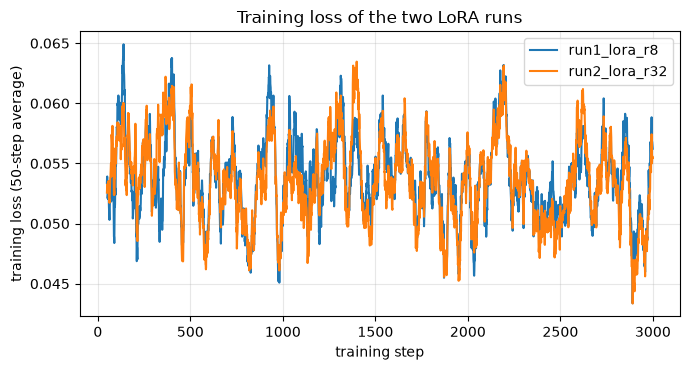

In [8]:
plt.figure(figsize=(7, 3.8))
for run_name, curve in curves.items():
    plt.plot(curve.rolling(50).mean(), label=run_name)
plt.xlabel("training step")
plt.ylabel("training loss (50-step average)")
plt.title("Training loss of the two LoRA runs")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(METRIC_DIR / "loss_curves.png", dpi=120)
plt.show()

## 8. Quick check that the LoRA weights change the output

One in-domain prompt, one seed: the base model and the two runs. This is only a sanity check that the weights load and have an effect. The real generation and evaluation are in notebook 3.

C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:  50%|█████     | 3/6 [00:00<00:00, 23.95it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 15.89it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 16.74it/s]


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


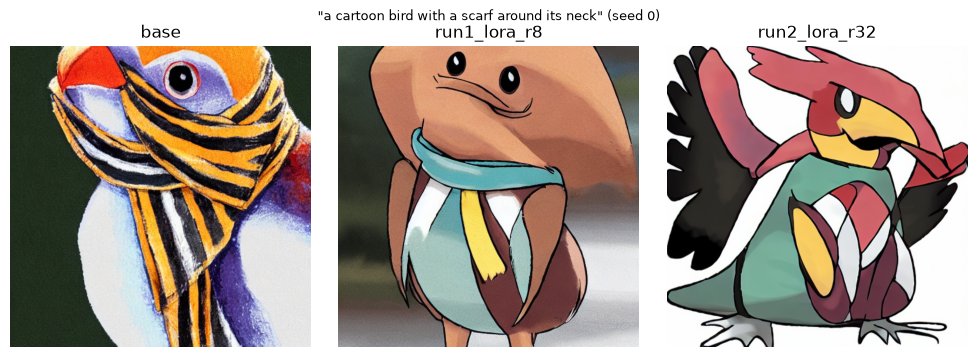

Mean pixel difference from the base image: {'run1_lora_r8': 53.9, 'run2_lora_r32': 78.2}


In [9]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL, torch_dtype=torch.float16, variant="fp16", safety_checker=None
).to("cuda")
pipe.set_progress_bar_config(disable=True)

prompt = prompts[0]["prompt"]
images = {}
for name in ["base"] + list(RUNS):
    if name != "base":
        pipe.load_lora_weights(str((RUN_DIR / name).resolve()))
    generator = torch.Generator("cuda").manual_seed(0)
    images[name] = pipe(prompt, num_inference_steps=30, generator=generator).images[0]
    if name != "base":
        pipe.unload_lora_weights()

figure, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for axis, (name, image) in zip(axes, images.items()):
    axis.imshow(image)
    axis.set_title(name)
    axis.axis("off")
plt.suptitle(f'"{prompt}" (seed 0)', fontsize=9)
plt.tight_layout()
plt.show()

# the images must differ if the LoRA weights are really applied
difference = {n: float(np.abs(np.asarray(images[n], dtype=np.float32) - np.asarray(images["base"], dtype=np.float32)).mean()) for n in RUNS}
print("Mean pixel difference from the base image:", {n: round(d, 1) for n, d in difference.items()})
assert all(d > 1 for d in difference.values()), "the LoRA weights had no effect"

del pipe
torch.cuda.empty_cache()

## 9. Summary

In [10]:
print(training_table[["run", "rank", "trainable_parameters", "learning_rate", "steps", "batch_size",
                      "peak_gpu_memory_gb", "training_minutes", "gpu_hours", "final_loss"]].to_string(index=False))
print(f"\nBoth runs stayed within the {MEMORY_LIMIT_GB} GB limit, so they also fit on a 16 GB GPU.")
print("Next: run p2_3_generate_evaluate.ipynb")

          run  rank  trainable_parameters  learning_rate  steps  batch_size  peak_gpu_memory_gb  training_minutes  gpu_hours  final_loss
 run1_lora_r8     8               1594368         0.0001   3000           4                3.70              16.2      0.271      0.0523
run2_lora_r32    32               6377472         0.0001   3000           4                3.75              16.1      0.269      0.0522

Both runs stayed within the 15 GB limit, so they also fit on a 16 GB GPU.
Next: run p2_3_generate_evaluate.ipynb
